In [1]:
import os, json, copy, warnings, gc, random
from pathlib import Path
from datetime import datetime

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from google.colab import drive
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.mixture import GaussianMixture
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score
from sklearn.ensemble import ExtraTreesRegressor, RandomForestRegressor
from lightgbm import LGBMRegressor
from xgboost import XGBRegressor

warnings.filterwarnings('ignore')
SEED = 42
random.seed(SEED); np.random.seed(SEED)

pd.set_option('display.max_columns', None)
pd.set_option('display.width', 180)

In [2]:
drive.mount('/content/drive')

DRIVE_DIR = Path('/content/drive/MyDrive')
INPUT_FILE = DRIVE_DIR / 'model_ready_category_dataset.csv'
OUT_DIR = DRIVE_DIR / 'model_4_cluster_based_rolling_origin_outputs'
OUT_DIR.mkdir(parents=True, exist_ok=True)

DATE_COL = 'week_start'
CATEGORY_COL = 'Product Category'
TARGET_COL = 'weekly_quantity'

SEASONAL_PERIOD = 52
EPS = 1e-12

OUTER_ORIGINS = {
    'spring_2025': '2025-04-07',
    'summer_2025': '2025-07-07',
    'early_autumn_2025': '2025-09-08',
    'q4_year_end_2025': '2025-10-06',
}
FORECAST_HORIZONS = [4, 8, 12]
MAX_HORIZON = 12
INNER_CV_HORIZON = 4
INNER_CV_OFFSETS_WEEKS = [12, 8, 4]

OPTIONAL_EXOGENOUS = ['transaction_count', 'active_customer_count']
EXOG_LAGS = [12, 26, 52]

print('Input:', INPUT_FILE)
print('Output:', OUT_DIR)

Mounted at /content/drive
Input: /content/drive/MyDrive/model_ready_category_dataset.csv
Output: /content/drive/MyDrive/model_4_cluster_based_rolling_origin_outputs


In [3]:
if not INPUT_FILE.exists():
    raise FileNotFoundError(INPUT_FILE)

raw = pd.read_csv(INPUT_FILE)
raw[DATE_COL] = pd.to_datetime(raw[DATE_COL])

required = [CATEGORY_COL, DATE_COL, TARGET_COL]
missing = [c for c in required if c not in raw.columns]
if missing:
    raise ValueError(f'Missing required columns: {missing}')

available_exog = [c for c in OPTIONAL_EXOGENOUS if c in raw.columns]
keep = required + available_exog
raw = raw[keep].copy()
raw = raw.dropna(subset=required).sort_values([CATEGORY_COL, DATE_COL])

if raw.duplicated([CATEGORY_COL, DATE_COL]).any():
    raise ValueError('Duplicate category-week observations detected.')

categories = sorted(raw[CATEGORY_COL].astype(str).unique())
raw[CATEGORY_COL] = raw[CATEGORY_COL].astype(str)
dataset_min, dataset_max = raw[DATE_COL].min(), raw[DATE_COL].max()
full_weeks = pd.date_range(dataset_min, dataset_max, freq='7D')

parts = []
for cat in categories:
    cols = [TARGET_COL] + available_exog
    x = raw[raw[CATEGORY_COL] == cat].set_index(DATE_COL)[cols].reindex(full_weeks)
    x.index.name = DATE_COL
    x[TARGET_COL] = x[TARGET_COL].fillna(0.0).clip(lower=0)
    for c in available_exog:
        x[c] = x[c].fillna(0.0).clip(lower=0)
    x[CATEGORY_COL] = cat
    parts.append(x.reset_index())

panel = pd.concat(parts, ignore_index=True).sort_values([CATEGORY_COL, DATE_COL]).reset_index(drop=True)

print('Shape:', panel.shape)
print('Categories:', len(categories))
print('Date range:', dataset_min.date(), 'to', dataset_max.date())
print('Optional operational variables:', available_exog if available_exog else 'none')
print('Operational lags:', EXOG_LAGS if available_exog else 'n/a')

Shape: (6200, 4)
Categories: 40
Date range: 2023-01-09 to 2025-12-22
Optional operational variables: ['transaction_count']
Operational lags: [12, 26, 52]


,scenario_id,outer_origin_label,outer_origin,horizon_weeks,test_start,test_end
0,spring_2025_h4,spring_2025,2025-04-07,4,2025-04-07,2025-04-28
1,spring_2025_h8,spring_2025,2025-04-07,8,2025-04-07,2025-05-26
2,spring_2025_h12,spring_2025,2025-04-07,12,2025-04-07,2025-06-23
3,summer_2025_h4,summer_2025,2025-07-07,4,2025-07-07,2025-07-28
4,summer_2025_h8,summer_2025,2025-07-07,8,2025-07-07,2025-08-25
5,summer_2025_h12,summer_2025,2025-07-07,12,2025-07-07,2025-09-22
6,early_autumn_2025_h4,early_autumn_2025,2025-09-08,4,2025-09-08,2025-09-29
7,early_autumn_2025_h8,early_autumn_2025,2025-09-08,8,2025-09-08,2025-10-27
8,early_autumn_2025_h12,early_autumn_2025,2025-09-08,12,2025-09-08,2025-11-24
9,q4_year_end_2025_h4,q4_year_end_2025,2025-10-06,4,2025-10-06,2025-10-27


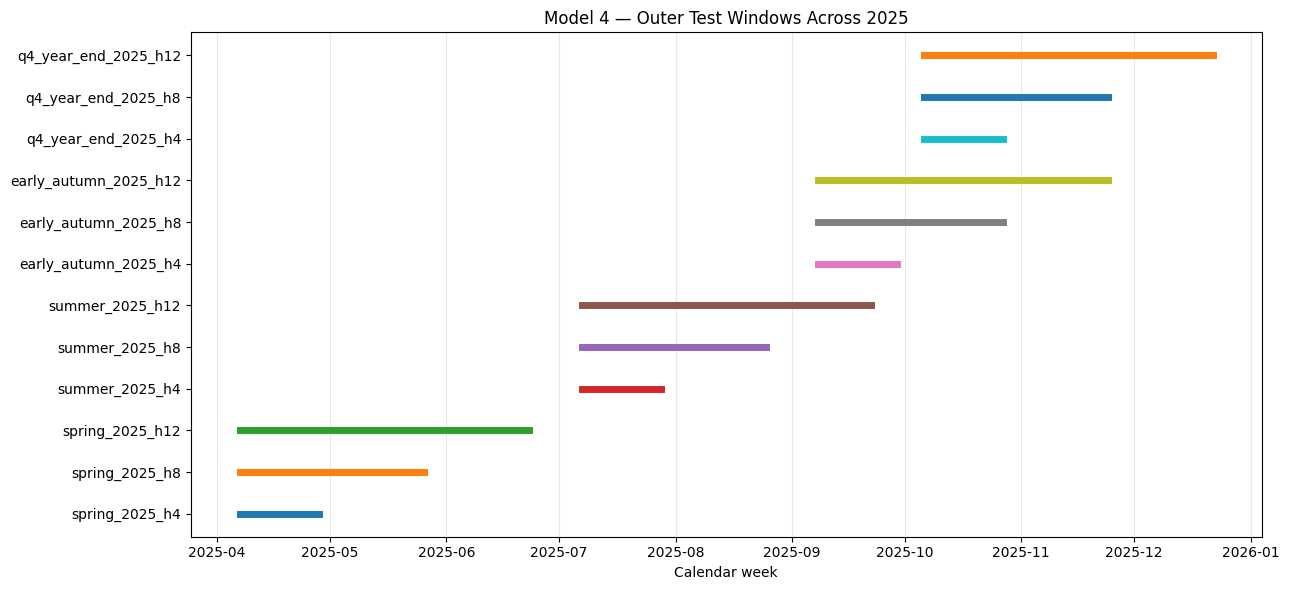

In [4]:
scenario_rows = []
for label, origin_s in OUTER_ORIGINS.items():
    origin = pd.Timestamp(origin_s)
    for h in FORECAST_HORIZONS:
        dates = pd.date_range(origin, periods=h, freq='7D')
        if dates[-1] > dataset_max:
            raise ValueError(f'{label}, h={h} exceeds dataset end.')
        scenario_rows.append({
            'scenario_id': f'{label}_h{h}',
            'outer_origin_label': label,
            'outer_origin': origin,
            'horizon_weeks': h,
            'test_start': dates[0],
            'test_end': dates[-1]
        })

scenarios = pd.DataFrame(scenario_rows)
scenarios.to_csv(OUT_DIR/'model_4_common_rolling_origin_scenarios.csv', index=False, encoding='utf-8-sig')
display(scenarios)

plt.figure(figsize=(13,6))
for i,r in scenarios.iterrows():
    plt.plot([r.test_start,r.test_end],[i,i],linewidth=5)
plt.yticks(range(len(scenarios)),scenarios.scenario_id)
plt.title('Model 4 — Outer Test Windows Across 2025')
plt.xlabel('Calendar week'); plt.grid(axis='x',alpha=.3); plt.tight_layout()
plt.savefig(OUT_DIR/'plot_outer_test_windows.png',dpi=160); plt.show()

In [5]:
def mae(a,p):
    a,p=np.asarray(a,float),np.asarray(p,float)
    return float(np.mean(np.abs(a-p)))

def rmse(a,p):
    a,p=np.asarray(a,float),np.asarray(p,float)
    return float(np.sqrt(np.mean((a-p)**2)))

def mape(a,p):
    a,p=np.asarray(a,float),np.asarray(p,float)
    mask=np.abs(a)>EPS
    return np.nan if mask.sum()==0 else float(np.mean(np.abs((a[mask]-p[mask])/a[mask]))*100)

def smape(a,p):
    a,p=np.asarray(a,float),np.asarray(p,float)
    d=np.abs(a)+np.abs(p)
    return float(np.mean(np.where(d>EPS,2*np.abs(a-p)/d,0))*100)

def mase_scale_info(y_train,m=52):
    y=np.asarray(y_train,float)
    if len(y)<=m:
        return np.nan,'insufficient_history'
    scale=float(np.mean(np.abs(y[m:]-y[:-m])))
    if not np.isfinite(scale):
        return np.nan,'non_finite_scale'
    if scale<=EPS:
        return np.nan,'zero_seasonal_scale'
    return scale,'valid'

def evaluate(a,p,y_train,m=52):
    scale,status=mase_scale_info(y_train,m)
    return {
        'MAE':mae(a,p),'RMSE':rmse(a,p),'MAPE':mape(a,p),
        'MAPE_N':int(np.sum(np.abs(np.asarray(a,float))>EPS)),
        'sMAPE':smape(a,p),
        'MASE':np.nan if not np.isfinite(scale) else mae(a,p)/scale,
        'MASE_scale':scale,'MASE_status':status
    }

print('MASE seasonal period:', SEASONAL_PERIOD)

MASE seasonal period: 52


In [6]:
def average_demand_interval(y):
    y=np.asarray(y,float)
    idx=np.where(y>0)[0]
    return float(len(y)) if len(idx)<=1 else float(np.mean(np.diff(idx)))

def trend_slope(y):
    y=np.asarray(y,float)
    if len(y)<3 or np.allclose(y,0): return 0.0
    return float(np.polyfit(np.arange(len(y)),y,1)[0])

def build_profiles(history):
    rows=[]
    for cat,g in history.groupby(CATEGORY_COL):
        g=g.sort_values(DATE_COL)
        y=g[TARGET_COL].values.astype(float)
        pos=y[y>0]
        mean=float(np.mean(y)); std=float(np.std(y,ddof=1)) if len(y)>1 else 0.0
        cv=std/mean if mean>EPS else 0.0
        adi=average_demand_interval(y)
        rows.append({
            CATEGORY_COL:cat,
            'mean_demand':mean,
            'median_demand':float(np.median(y)),
            'std_demand':std,
            'cv':cv,'cv2':cv**2,
            'zero_ratio':float(np.mean(y==0)),
            'positive_ratio':float(np.mean(y>0)),
            'ADI':adi,
            'intermittency_score':float(np.mean(y==0))*adi,
            'max_demand':float(np.max(y)) if len(y) else 0.0,
            'spike_ratio':float(np.max(y)/mean) if mean>EPS else 0.0,
            'nonzero_mean':float(np.mean(pos)) if len(pos) else 0.0,
            'nonzero_std':float(np.std(pos,ddof=1)) if len(pos)>1 else 0.0,
            'trend_slope':trend_slope(y),
            'recent_4_mean':float(np.mean(y[-4:])),
            'recent_8_mean':float(np.mean(y[-8:])),
            'recent_12_mean':float(np.mean(y[-12:])),
        })
    return pd.DataFrame(rows)

CLUSTER_FEATURES=[
    'mean_demand','median_demand','std_demand','cv','cv2','zero_ratio','positive_ratio',
    'ADI','intermittency_score','max_demand','spike_ratio','nonzero_mean','nonzero_std',
    'trend_slope','recent_4_mean','recent_8_mean','recent_12_mean'
]
LOG_CLUSTER_COLS=[
    'mean_demand','median_demand','std_demand','cv','cv2','ADI','intermittency_score',
    'max_demand','spike_ratio','nonzero_mean','nonzero_std','recent_4_mean','recent_8_mean','recent_12_mean'
]

CLUSTER_CANDIDATES=[
    {'cluster_config_id':f'{alg}_k{k}','algorithm':alg,'k':k}
    for alg in ['kmeans','agglomerative','gmm'] for k in [2,3,4,5]
]
display(pd.DataFrame(CLUSTER_CANDIDATES))
print('TOTAL CLUSTERING CANDIDATES:',len(CLUSTER_CANDIDATES))

,cluster_config_id,algorithm,k
0,kmeans_k2,kmeans,2
1,kmeans_k3,kmeans,3
2,kmeans_k4,kmeans,4
3,kmeans_k5,kmeans,5
4,agglomerative_k2,agglomerative,2
5,agglomerative_k3,agglomerative,3
6,agglomerative_k4,agglomerative,4
7,agglomerative_k5,agglomerative,5
8,gmm_k2,gmm,2
9,gmm_k3,gmm,3


TOTAL CLUSTERING CANDIDATES: 12


In [7]:
def cluster_categories(history, config):
    prof=build_profiles(history)
    X=prof[CLUSTER_FEATURES].replace([np.inf,-np.inf],np.nan).fillna(0).copy()
    for c in LOG_CLUSTER_COLS:
        X[c]=np.sign(X[c])*np.log1p(np.abs(X[c]))
    scaler=StandardScaler()
    Z=scaler.fit_transform(X)

    k=int(config['k']); alg=config['algorithm']
    if alg=='kmeans':
        model=KMeans(n_clusters=k,random_state=SEED,n_init=30)
        raw_labels=model.fit_predict(Z)
    elif alg=='agglomerative':
        model=AgglomerativeClustering(n_clusters=k,linkage='ward')
        raw_labels=model.fit_predict(Z)
    elif alg=='gmm':
        model=GaussianMixture(n_components=k,random_state=SEED,covariance_type='full',reg_covar=1e-5)
        raw_labels=model.fit_predict(Z)
    else:
        raise ValueError(alg)

    prof['raw_cluster']=raw_labels
    order=(prof.groupby('raw_cluster')['mean_demand'].mean().sort_values().index.tolist())
    remap={old:new for new,old in enumerate(order)}
    prof['cluster']=prof['raw_cluster'].map(remap).astype(int)

    sil=np.nan if len(np.unique(raw_labels))<2 else float(silhouette_score(Z,raw_labels))
    db=np.nan if len(np.unique(raw_labels))<2 else float(davies_bouldin_score(Z,raw_labels))
    ch=np.nan if len(np.unique(raw_labels))<2 else float(calinski_harabasz_score(Z,raw_labels))
    return prof, {'silhouette':sil,'davies_bouldin':db,'calinski_harabasz':ch}

In [8]:
LAGS=[1,2,4,8,12,26,52]
ROLLING_WINDOWS=[4,8,12,26]

def calendar_features(date):
    d=pd.Timestamp(date)
    w=int(d.isocalendar().week)
    return {
        'year':d.year,'month':d.month,'quarter':d.quarter,'week_of_year':w,
        'week_sin':np.sin(2*np.pi*w/52.0),'week_cos':np.cos(2*np.pi*w/52.0),
        'month_sin':np.sin(2*np.pi*d.month/12.0),'month_cos':np.cos(2*np.pi*d.month/12.0)
    }

observed_exog={}
for cat in categories:
    d=panel[panel[CATEGORY_COL]==cat].set_index(DATE_COL)
    observed_exog[cat]={c:d[c].to_dict() for c in available_exog}

def feature_row(cat,date,history_values):
    y=np.asarray(history_values,float)
    r=calendar_features(date)
    for lag in LAGS:
        r[f'lag_{lag}']=float(y[-lag]) if len(y)>=lag else 0.0
    for w in ROLLING_WINDOWS:
        z=y[-w:] if len(y) else np.array([0.0])
        r[f'rolling_mean_{w}']=float(np.mean(z))
        r[f'rolling_std_{w}']=float(np.std(z,ddof=1)) if len(z)>1 else 0.0
        r[f'rolling_min_{w}']=float(np.min(z))
        r[f'rolling_max_{w}']=float(np.max(z))
        r[f'zero_ratio_{w}']=float(np.mean(z==0))
        r[f'positive_ratio_{w}']=float(np.mean(z>0))
    for c in available_exog:
        for lag in EXOG_LAGS:
            src=pd.Timestamp(date)-pd.Timedelta(weeks=lag)
            r[f'{c}_lag_{lag}']=float(observed_exog[cat][c].get(src,0.0))
    return r

CALENDAR_FEATURES=['year','month','quarter','week_of_year','week_sin','week_cos','month_sin','month_cos']
TARGET_FEATURES=[f'lag_{l}' for l in LAGS]
for w in ROLLING_WINDOWS:
    TARGET_FEATURES += [f'rolling_mean_{w}',f'rolling_std_{w}',f'rolling_min_{w}',f'rolling_max_{w}',
                        f'zero_ratio_{w}',f'positive_ratio_{w}']
EXOG_FEATURES=[f'{c}_lag_{l}' for c in available_exog for l in EXOG_LAGS]
FEATURE_COLS=CALENDAR_FEATURES+TARGET_FEATURES+EXOG_FEATURES

print('Forecasting features:',len(FEATURE_COLS))
print(FEATURE_COLS)

Forecasting features: 42
['year', 'month', 'quarter', 'week_of_year', 'week_sin', 'week_cos', 'month_sin', 'month_cos', 'lag_1', 'lag_2', 'lag_4', 'lag_8', 'lag_12', 'lag_26', 'lag_52', 'rolling_mean_4', 'rolling_std_4', 'rolling_min_4', 'rolling_max_4', 'zero_ratio_4', 'positive_ratio_4', 'rolling_mean_8', 'rolling_std_8', 'rolling_min_8', 'rolling_max_8', 'zero_ratio_8', 'positive_ratio_8', 'rolling_mean_12', 'rolling_std_12', 'rolling_min_12', 'rolling_max_12', 'zero_ratio_12', 'positive_ratio_12', 'rolling_mean_26', 'rolling_std_26', 'rolling_min_26', 'rolling_max_26', 'zero_ratio_26', 'positive_ratio_26', 'transaction_count_lag_12', 'transaction_count_lag_26', 'transaction_count_lag_52']


In [9]:
def make_supervised(history, cluster_categories_set):
    rows=[]
    for cat in sorted(cluster_categories_set):
        d=history[history[CATEGORY_COL]==cat].sort_values(DATE_COL)
        vals=d[TARGET_COL].values.astype(float)
        dates=d[DATE_COL].tolist()
        for i in range(SEASONAL_PERIOD,len(vals)):
            r=feature_row(cat,dates[i],vals[:i])
            r[TARGET_COL]=vals[i]
            rows.append(r)
    return pd.DataFrame(rows)

def croston_forecast(y,h,alpha=0.1):
    y=np.asarray(y,float)
    nz=np.where(y>0)[0]
    if len(nz)==0: return np.zeros(h)
    z=y[nz[0]]; p=max(nz[0]+1,1); q=1
    last=nz[0]
    for idx in nz[1:]:
        interval=idx-last
        z=z+alpha*(y[idx]-z)
        p=p+alpha*(interval-p)
        last=idx
    f=max(z/max(p,EPS),0.0)
    return np.repeat(f,h)

def tsb_forecast(y,h,alpha=0.1,beta=0.1):
    y=np.asarray(y,float)
    if len(y)==0: return np.zeros(h)
    p=1.0 if y[0]>0 else 0.0
    z=y[0] if y[0]>0 else (np.mean(y[y>0]) if np.any(y>0) else 0.0)
    for v in y[1:]:
        occ=1.0 if v>0 else 0.0
        p=p+beta*(occ-p)
        if v>0: z=z+alpha*(v-z)
    return np.repeat(max(p*z,0.0),h)

EXPERT_IDS=[
    'seasonal_naive_52','moving_average_4','moving_average_12','croston','tsb',
    'extra_trees','lightgbm','xgboost'
]

def make_ml_expert(expert_id):
    if expert_id=='extra_trees':
        return ExtraTreesRegressor(n_estimators=350,max_depth=10,min_samples_leaf=2,
                                   random_state=SEED,n_jobs=-1)
    if expert_id=='lightgbm':
        return LGBMRegressor(n_estimators=400,learning_rate=0.03,num_leaves=15,max_depth=6,
                             min_child_samples=8,subsample=.9,colsample_bytree=.9,
                             reg_alpha=.1,reg_lambda=1.0,random_state=SEED,verbose=-1,n_jobs=-1)
    if expert_id=='xgboost':
        return XGBRegressor(n_estimators=400,learning_rate=0.03,max_depth=5,min_child_weight=3,
                            subsample=.9,colsample_bytree=.9,reg_alpha=.1,reg_lambda=1.0,
                            objective='reg:squarederror',random_state=SEED,n_jobs=-1)
    raise ValueError(expert_id)

print('EXPERTS:',EXPERT_IDS)

EXPERTS: ['seasonal_naive_52', 'moving_average_4', 'moving_average_12', 'croston', 'tsb', 'extra_trees', 'lightgbm', 'xgboost']


In [10]:
def forecast_cluster_expert(history, cats, forecast_dates, expert_id, origin):
    forecast_dates=pd.to_datetime(forecast_dates)
    outputs=[]

    if expert_id in ['seasonal_naive_52','moving_average_4','moving_average_12','croston','tsb']:
        for cat in sorted(cats):
            y=history[history[CATEGORY_COL]==cat].sort_values(DATE_COL)[TARGET_COL].values.astype(float)
            h=len(forecast_dates)
            if expert_id=='seasonal_naive_52':
                preds=np.array([y[-52+i] if len(y)>=52 and (-52+i)<0 else (y[-1] if len(y) else 0.0)
                                for i in range(h)],float)
            elif expert_id=='moving_average_4':
                preds=np.repeat(np.mean(y[-4:]) if len(y) else 0.0,h)
            elif expert_id=='moving_average_12':
                preds=np.repeat(np.mean(y[-12:]) if len(y) else 0.0,h)
            elif expert_id=='croston':
                preds=croston_forecast(y,h)
            else:
                preds=tsb_forecast(y,h)
            for d,p in zip(forecast_dates,preds):
                outputs.append({CATEGORY_COL:cat,DATE_COL:d,'y_pred':max(float(p),0.0)})
        return pd.DataFrame(outputs)

    sup=make_supervised(history,cats)
    if sup.empty:
        raise ValueError(f'No supervised rows for expert {expert_id}.')
    model=make_ml_expert(expert_id)
    model.fit(sup[FEATURE_COLS].astype(float),sup[TARGET_COL].astype(float))

    working={}
    for cat in sorted(cats):
        d=history[history[CATEGORY_COL]==cat].sort_values(DATE_COL)
        working[cat]=d[TARGET_COL].values.astype(float).tolist()

    for d in forecast_dates:
        for cat in sorted(cats):
            for lag in EXOG_LAGS:
                if available_exog:
                    assert pd.Timestamp(d)-pd.Timedelta(weeks=lag) < pd.Timestamp(origin)
            row=feature_row(cat,d,working[cat])
            pred=float(model.predict(pd.DataFrame([row])[FEATURE_COLS].astype(float))[0])
            pred=max(pred,0.0)
            outputs.append({CATEGORY_COL:cat,DATE_COL:d,'y_pred':pred})
            working[cat].append(pred)
    return pd.DataFrame(outputs)

def score_categories(pred,actual,history):
    merged=actual[[CATEGORY_COL,DATE_COL,TARGET_COL]].merge(pred,on=[CATEGORY_COL,DATE_COL],how='left')
    if merged.y_pred.isna().any():
        raise ValueError('Missing predictions.')
    rows=[]
    for cat in sorted(merged[CATEGORY_COL].unique()):
        q=merged[merged[CATEGORY_COL]==cat].sort_values(DATE_COL)
        hist=history[history[CATEGORY_COL]==cat].sort_values(DATE_COL)[TARGET_COL].values
        rows.append({CATEGORY_COL:cat,**evaluate(q[TARGET_COL].values,q.y_pred.values,hist,SEASONAL_PERIOD)})
    return pd.DataFrame(rows),merged

def inner_folds(outer_origin):
    ans=[]
    for fold,offset in enumerate(INNER_CV_OFFSETS_WEEKS,1):
        vo=pd.Timestamp(outer_origin)-pd.Timedelta(weeks=offset)
        dates=pd.date_range(vo,periods=INNER_CV_HORIZON,freq='7D')
        if dates[-1]>=pd.Timestamp(outer_origin):
            raise AssertionError('Inner fold overlaps outer test.')
        ans.append((fold,vo,dates))
    return ans

In [11]:
all_trial_rows=[]
all_expert_fold_rows=[]
selected_structures=[]

for origin_label,origin_s in OUTER_ORIGINS.items():
    origin=pd.Timestamp(origin_s)
    print('\n'+'='*110)
    print('MODEL 4 TUNING FOR OUTER ORIGIN:',origin_label,origin.date())
    print('='*110)

    for trial_no,cfg in enumerate(CLUSTER_CANDIDATES,1):
        print(f"Clustering trial {trial_no:02d}/{len(CLUSTER_CANDIDATES)} | {cfg['cluster_config_id']}")
        fold_cluster_quality=[]
        local_rows=[]

        for fold,vo,vdates in inner_folds(origin):
            train=panel[panel[DATE_COL]<vo].copy()
            actual=panel[panel[DATE_COL].isin(vdates)].copy()
            assert train[DATE_COL].max()<actual[DATE_COL].min()
            assert actual[DATE_COL].max()<origin

            prof,quality=cluster_categories(train,cfg)
            cmap=prof.set_index(CATEGORY_COL)['cluster'].to_dict()
            fold_cluster_quality.append({'fold':fold,**quality})

            for cluster in sorted(prof.cluster.unique()):
                cats=prof.loc[prof.cluster==cluster,CATEGORY_COL].tolist()
                for expert_id in EXPERT_IDS:
                    row={
                        'outer_origin_label':origin_label,'outer_origin':origin,
                        'cluster_config_id':cfg['cluster_config_id'],'algorithm':cfg['algorithm'],'k':cfg['k'],
                        'inner_fold':fold,'validation_origin':vo,'cluster':int(cluster),'expert_id':expert_id
                    }
                    try:
                        pred=forecast_cluster_expert(train,cats,vdates,expert_id,vo)
                        cat_scores,_=score_categories(pred,actual[actual[CATEGORY_COL].isin(cats)],train)
                        row.update({
                            'status':'ok','mean_MASE':cat_scores.MASE.mean(),'median_MASE':cat_scores.MASE.median(),
                            'mean_MAE':cat_scores.MAE.mean(),'mean_RMSE':cat_scores.RMSE.mean(),
                            'mean_MAPE':cat_scores.MAPE.mean(),'mean_sMAPE':cat_scores.sMAPE.mean(),
                            'valid_MASE_N':int(cat_scores.MASE.notna().sum())
                        })
                    except Exception as e:
                        row.update({'status':'failed','mean_MASE':np.nan,'median_MASE':np.nan,
                                    'mean_MAE':np.nan,'mean_RMSE':np.nan,'mean_MAPE':np.nan,
                                    'mean_sMAPE':np.nan,'valid_MASE_N':0,'error':str(e)})
                    local_rows.append(row)

        local=pd.DataFrame(local_rows)
        all_expert_fold_rows.extend(local_rows)

        held_scores=[]
        for held_fold in [1,2,3]:
            train_folds=local[(local.inner_fold!=held_fold)&(local.status=='ok')]
            held=local[(local.inner_fold==held_fold)&(local.status=='ok')]
            for cluster in sorted(held.cluster.unique()):
                trc=train_folds[train_folds.cluster==cluster]
                hc=held[held.cluster==cluster]
                if trc.empty or hc.empty: continue
                agg=(trc.groupby('expert_id',as_index=False)
                     .agg(sel_MASE=('mean_MASE','mean'),sel_sMAPE=('mean_sMAPE','mean'),
                          sel_RMSE=('mean_RMSE','mean'),sel_MAE=('mean_MAE','mean')))
                if agg.sel_MASE.notna().any():
                    best=agg.sort_values(['sel_MASE','sel_RMSE','sel_MAE'],na_position='last').iloc[0]
                else:
                    best=agg.sort_values(['sel_sMAPE','sel_RMSE','sel_MAE']).iloc[0]
                z=hc[hc.expert_id==best.expert_id]
                if not z.empty:
                    held_scores.append(z.iloc[0].to_dict())

        hs=pd.DataFrame(held_scores)
        qdf=pd.DataFrame(fold_cluster_quality)
        trial_row={
            'outer_origin_label':origin_label,'outer_origin':origin,
            'trial_id':trial_no,'cluster_config_id':cfg['cluster_config_id'],
            'algorithm':cfg['algorithm'],'k':cfg['k'],
            'cv_mean_MASE':hs.mean_MASE.mean() if not hs.empty else np.nan,
            'cv_std_MASE':hs.mean_MASE.std() if not hs.empty else np.nan,
            'cv_mean_sMAPE':hs.mean_sMAPE.mean() if not hs.empty else np.nan,
            'cv_mean_RMSE':hs.mean_RMSE.mean() if not hs.empty else np.nan,
            'cv_mean_MAE':hs.mean_MAE.mean() if not hs.empty else np.nan,
            'mean_silhouette':qdf.silhouette.mean(),
            'mean_davies_bouldin':qdf.davies_bouldin.mean(),
            'held_cluster_scores_N':len(hs)
        }
        all_trial_rows.append(trial_row)
        pd.DataFrame(all_trial_rows).to_csv(OUT_DIR/'model_4_inner_cv_clustering_trials.csv',index=False,encoding='utf-8-sig')
        pd.DataFrame(all_expert_fold_rows).to_csv(OUT_DIR/'model_4_inner_cv_expert_results.csv',index=False,encoding='utf-8-sig')

    trials=pd.DataFrame([r for r in all_trial_rows if r['outer_origin_label']==origin_label])
    if trials.cv_mean_MASE.notna().any():
        ranked=trials.sort_values(['cv_mean_MASE','cv_std_MASE','cv_mean_RMSE','cv_mean_MAE'],na_position='last')
        selection_metric='held_fold_mean_MASE'
    else:
        ranked=trials.sort_values(['cv_mean_sMAPE','cv_mean_RMSE','cv_mean_MAE'])
        selection_metric='held_fold_mean_sMAPE_fallback'
    best_trial=ranked.iloc[0]
    best_cfg=next(x for x in CLUSTER_CANDIDATES if x['cluster_config_id']==best_trial.cluster_config_id)

    local=pd.DataFrame([r for r in all_expert_fold_rows
                        if r['outer_origin_label']==origin_label and
                        r['cluster_config_id']==best_cfg['cluster_config_id'] and r['status']=='ok'])
    final_experts={}
    for cluster in sorted(local.cluster.unique()):
        z=local[local.cluster==cluster]
        agg=(z.groupby('expert_id',as_index=False)
             .agg(mean_MASE=('mean_MASE','mean'),std_MASE=('mean_MASE','std'),
                  mean_sMAPE=('mean_sMAPE','mean'),mean_RMSE=('mean_RMSE','mean'),mean_MAE=('mean_MAE','mean')))
        if agg.mean_MASE.notna().any():
            b=agg.sort_values(['mean_MASE','std_MASE','mean_RMSE','mean_MAE'],na_position='last').iloc[0]
        else:
            b=agg.sort_values(['mean_sMAPE','mean_RMSE','mean_MAE']).iloc[0]
        final_experts[int(cluster)]=b.expert_id

    selected_structures.append({
        'outer_origin_label':origin_label,'outer_origin':origin,
        'cluster_config_id':best_cfg['cluster_config_id'],'algorithm':best_cfg['algorithm'],'k':best_cfg['k'],
        'selection_metric':selection_metric,'cv_mean_MASE':best_trial.cv_mean_MASE,
        'cv_mean_sMAPE':best_trial.cv_mean_sMAPE,'cluster_experts_json':json.dumps(final_experts)
    })
    print('SELECTED CLUSTERING:',best_cfg['cluster_config_id'])
    print('SELECTED CLUSTER EXPERTS:',final_experts)

selected_df=pd.DataFrame(selected_structures)
selected_df.to_csv(OUT_DIR/'model_4_selected_structures.csv',index=False,encoding='utf-8-sig')
display(selected_df)


MODEL 4 TUNING FOR OUTER ORIGIN: spring_2025 2025-04-07
Clustering trial 01/12 | kmeans_k2
Clustering trial 02/12 | kmeans_k3
Clustering trial 03/12 | kmeans_k4
Clustering trial 04/12 | kmeans_k5
Clustering trial 05/12 | agglomerative_k2
Clustering trial 06/12 | agglomerative_k3
Clustering trial 07/12 | agglomerative_k4
Clustering trial 08/12 | agglomerative_k5
Clustering trial 09/12 | gmm_k2
Clustering trial 10/12 | gmm_k3
Clustering trial 11/12 | gmm_k4
Clustering trial 12/12 | gmm_k5
SELECTED CLUSTERING: kmeans_k2
SELECTED CLUSTER EXPERTS: {0: 'moving_average_4', 1: 'seasonal_naive_52'}

MODEL 4 TUNING FOR OUTER ORIGIN: summer_2025 2025-07-07
Clustering trial 01/12 | kmeans_k2
Clustering trial 02/12 | kmeans_k3
Clustering trial 03/12 | kmeans_k4
Clustering trial 04/12 | kmeans_k5
Clustering trial 05/12 | agglomerative_k2
Clustering trial 06/12 | agglomerative_k3
Clustering trial 07/12 | agglomerative_k4
Clustering trial 08/12 | agglomerative_k5
Clustering trial 09/12 | gmm_k2
Clust

,outer_origin_label,outer_origin,cluster_config_id,algorithm,k,selection_metric,cv_mean_MASE,cv_mean_sMAPE,cluster_experts_json
0,spring_2025,2025-04-07,kmeans_k2,kmeans,2,held_fold_mean_MASE,1.339598,95.437420,"{""0"": ""moving_average_4"", ""1"": ""seasonal_naive..."
1,summer_2025,2025-07-07,kmeans_k4,kmeans,4,held_fold_mean_MASE,0.618792,55.717455,"{""0"": ""croston"", ""1"": ""moving_average_4"", ""2"":..."
2,early_autumn_2025,2025-09-08,agglomerative_k4,agglomerative,4,held_fold_mean_MASE,0.339562,68.547634,"{""0"": ""croston"", ""1"": ""moving_average_4"", ""2"":..."
3,q4_year_end_2025,2025-10-06,gmm_k2,gmm,2,held_fold_mean_MASE,0.917125,109.132915,"{""0"": ""moving_average_4"", ""1"": ""lightgbm""}"


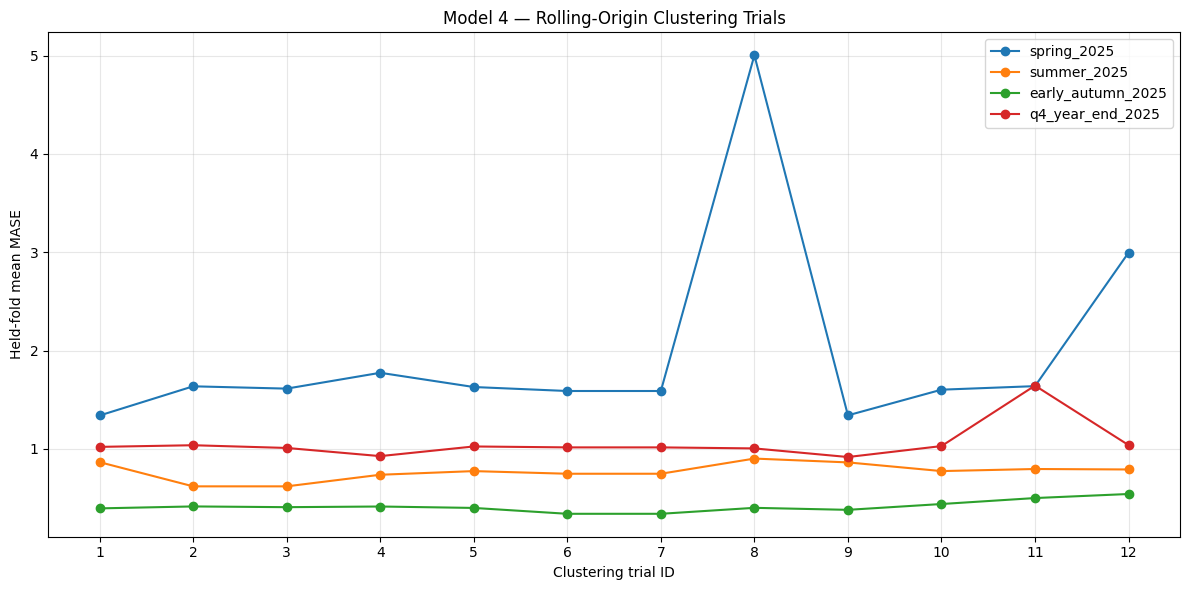

In [12]:
trials_df=pd.DataFrame(all_trial_rows)
plt.figure(figsize=(12,6))
for label in OUTER_ORIGINS:
    q=trials_df[trials_df.outer_origin_label==label].sort_values('trial_id')
    plt.plot(q.trial_id,q.cv_mean_MASE,marker='o',label=label)
plt.xlabel('Clustering trial ID'); plt.ylabel('Held-fold mean MASE')
plt.title('Model 4 — Rolling-Origin Clustering Trials')
plt.xticks(range(1,len(CLUSTER_CANDIDATES)+1))
plt.grid(alpha=.3); plt.legend(); plt.tight_layout()
plt.savefig(OUT_DIR/'plot_clustering_trials.png',dpi=160); plt.show()

In [13]:
outer_results=[]
outer_forecasts=[]
outer_cluster_profiles=[]

for _,sel in selected_df.iterrows():
    label=sel.outer_origin_label
    origin=pd.Timestamp(sel.outer_origin)
    cfg={'cluster_config_id':sel.cluster_config_id,'algorithm':sel.algorithm,'k':int(sel.k)}
    experts={int(k):v for k,v in json.loads(sel.cluster_experts_json).items()}

    print('\n'+'='*100)
    print('OUTER TEST:',label,'| clustering:',cfg['cluster_config_id'],'| experts:',experts)
    print('='*100)

    train=panel[panel[DATE_COL]<origin].copy()
    assert train[DATE_COL].max()<origin

    prof,quality=cluster_categories(train,cfg)
    prof['outer_origin_label']=label
    prof['outer_origin']=origin
    prof['selected_cluster_config']=cfg['cluster_config_id']
    outer_cluster_profiles.append(prof)

    max_dates=pd.date_range(origin,periods=MAX_HORIZON,freq='7D')
    pred_parts=[]
    for cluster in sorted(prof.cluster.unique()):
        cats=prof.loc[prof.cluster==cluster,CATEGORY_COL].tolist()
        if cluster not in experts:
            raise ValueError(f'No selected expert for canonical cluster {cluster}.')
        pred=forecast_cluster_expert(train,cats,max_dates,experts[cluster],origin)
        pred['cluster']=int(cluster)
        pred['expert_id']=experts[cluster]
        pred_parts.append(pred)
    pred12=pd.concat(pred_parts,ignore_index=True)

    for h in FORECAST_HORIZONS:
        dates=max_dates[:h]
        actual=panel[panel[DATE_COL].isin(dates)].copy()
        pred=pred12[pred12[DATE_COL].isin(dates)].copy()
        cat_scores,merged=score_categories(pred,actual,train)
        meta=prof[[CATEGORY_COL,'cluster']].merge(
            pd.DataFrame({'cluster':list(experts.keys()),'expert_id':[experts[k] for k in experts]}),
            on='cluster',how='left'
        )
        cat_scores=cat_scores.merge(meta,on=CATEGORY_COL,how='left')
        sid=f'{label}_h{h}'

        for _,r in cat_scores.iterrows():
            outer_results.append({
                'scenario_id':sid,'outer_origin_label':label,'outer_origin':origin,
                'horizon_weeks':h,'test_start':dates[0],'test_end':dates[-1],
                CATEGORY_COL:r[CATEGORY_COL],'cluster':r.cluster,'expert_id':r.expert_id,
                'selected_cluster_config':cfg['cluster_config_id'],
                'MAE':r.MAE,'RMSE':r.RMSE,'MAPE':r.MAPE,'MAPE_N':r.MAPE_N,
                'sMAPE':r.sMAPE,'MASE':r.MASE,'MASE_scale':r.MASE_scale,'MASE_status':r.MASE_status
            })

        merged=merged.merge(meta,on=CATEGORY_COL,how='left')
        merged=merged.rename(columns={TARGET_COL:'y_true'})
        merged['scenario_id']=sid; merged['outer_origin_label']=label; merged['outer_origin']=origin
        merged['horizon_weeks']=h; merged['selected_cluster_config']=cfg['cluster_config_id']
        merged['absolute_error']=np.abs(merged.y_true-merged.y_pred)
        outer_forecasts.append(merged)

test_df=pd.DataFrame(outer_results)
forecasts_df=pd.concat(outer_forecasts,ignore_index=True)
profiles_df=pd.concat(outer_cluster_profiles,ignore_index=True)

test_df.to_csv(OUT_DIR/'model_4_outer_test_results.csv',index=False,encoding='utf-8-sig')
forecasts_df.to_csv(OUT_DIR/'model_4_outer_forecasts.csv',index=False,encoding='utf-8-sig')
profiles_df.to_csv(OUT_DIR/'model_4_outer_cluster_profiles.csv',index=False,encoding='utf-8-sig')

print('\nOUTER BACKTEST COMPLETE')
print('Category-level outer evaluations:',len(test_df))
print('Expected:',len(categories)*len(OUTER_ORIGINS)*len(FORECAST_HORIZONS))
print('Valid MASE:',test_df.MASE.notna().sum(),'| Undefined MASE:',test_df.MASE.isna().sum())


OUTER TEST: spring_2025 | clustering: kmeans_k2 | experts: {0: 'moving_average_4', 1: 'seasonal_naive_52'}

OUTER TEST: summer_2025 | clustering: kmeans_k4 | experts: {0: 'croston', 1: 'moving_average_4', 2: 'moving_average_4', 3: 'lightgbm'}

OUTER TEST: early_autumn_2025 | clustering: agglomerative_k4 | experts: {0: 'croston', 1: 'moving_average_4', 2: 'moving_average_4', 3: 'lightgbm'}

OUTER TEST: q4_year_end_2025 | clustering: gmm_k2 | experts: {0: 'moving_average_4', 1: 'lightgbm'}

OUTER BACKTEST COMPLETE
Category-level outer evaluations: 480
Expected: 480
Valid MASE: 468 | Undefined MASE: 12


SCENARIO SUMMARY


,scenario_id,outer_origin_label,horizon_weeks,MAE,RMSE,MAPE,sMAPE,MASE,median_MASE,valid_MASE_N
0,early_autumn_2025_h12,early_autumn_2025,12,71.016544,102.173785,139.368818,103.680770,1.336991,0.540173,39
1,early_autumn_2025_h4,early_autumn_2025,4,126.596653,152.522163,71.661498,103.465361,2.435336,0.841986,39
2,early_autumn_2025_h8,early_autumn_2025,8,95.812170,122.951274,76.762237,100.513962,1.799955,0.750000,39
3,q4_year_end_2025_h12,q4_year_end_2025,12,47.824710,61.269956,322.486057,146.063071,2.455956,0.730868,39
4,q4_year_end_2025_h4,q4_year_end_2025,4,83.566866,90.410631,156.510635,127.872406,3.752980,1.392382,39
5,q4_year_end_2025_h8,q4_year_end_2025,8,61.968367,72.548622,371.360158,142.331248,3.271494,0.969572,39
6,spring_2025_h12,spring_2025,12,66.581250,89.329450,155.279953,79.489591,1.111557,0.591339,39
7,spring_2025_h4,spring_2025,4,102.000000,119.157602,106.756543,64.670759,1.339413,0.622265,39
8,spring_2025_h8,spring_2025,8,80.234375,103.217339,105.061038,74.904640,1.228207,0.612210,39
9,summer_2025_h12,summer_2025,12,61.934240,103.434039,187.554516,121.371950,1.121517,0.513237,39


OVERALL SUMMARY


,mean_MAE,mean_RMSE,mean_MAPE,mean_sMAPE,mean_MASE,median_MASE,valid_MASE_evaluations,undefined_MASE_evaluations,n_outer_evaluations
0,70.656172,90.433673,187.388726,107.389743,1.71034,0.564621,468,12,480


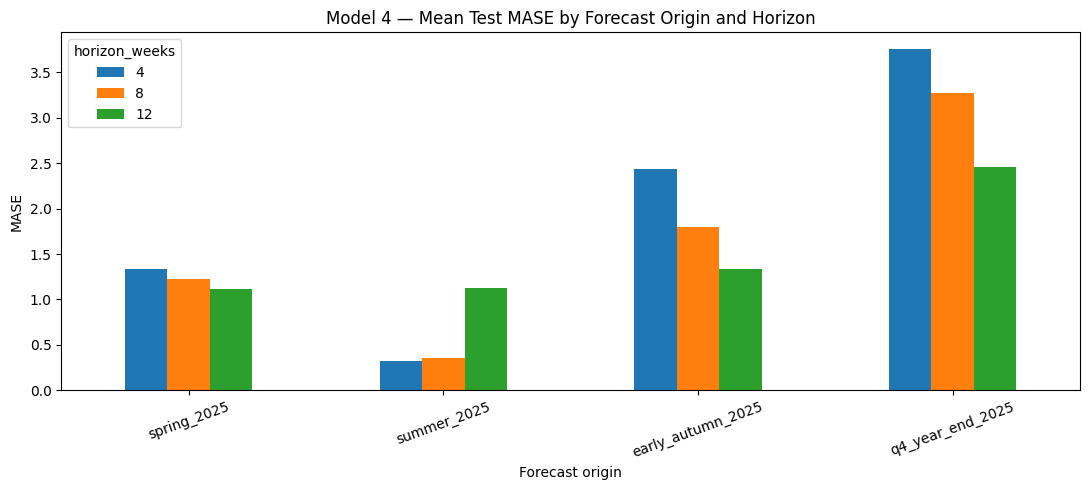

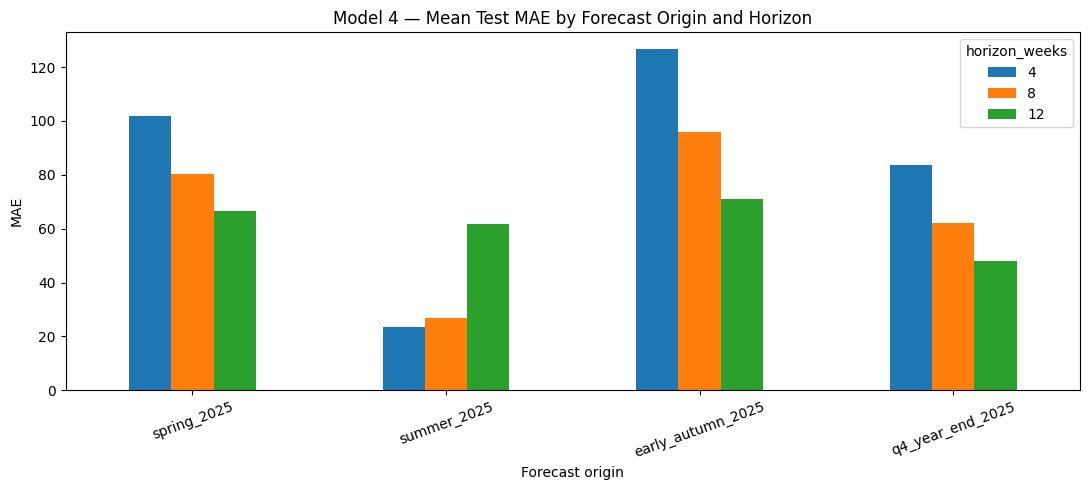

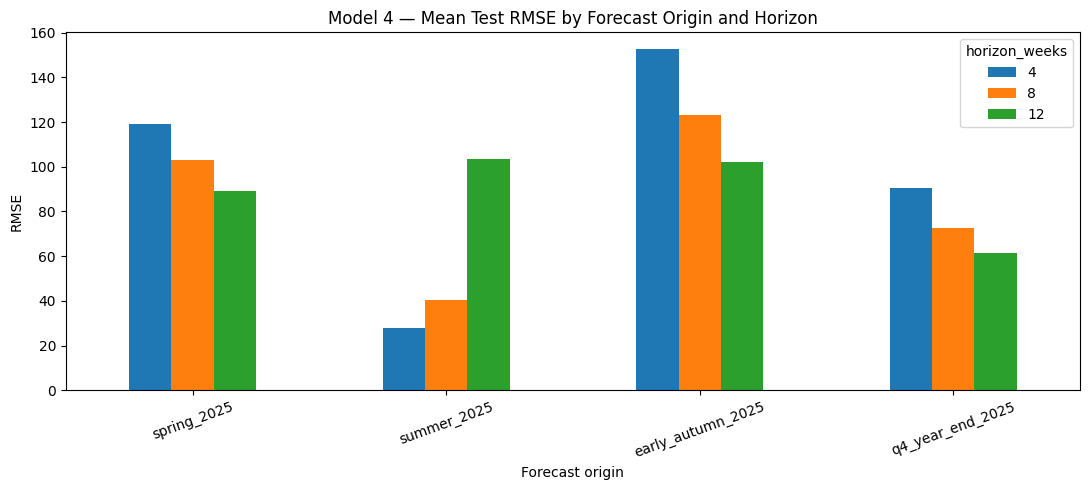

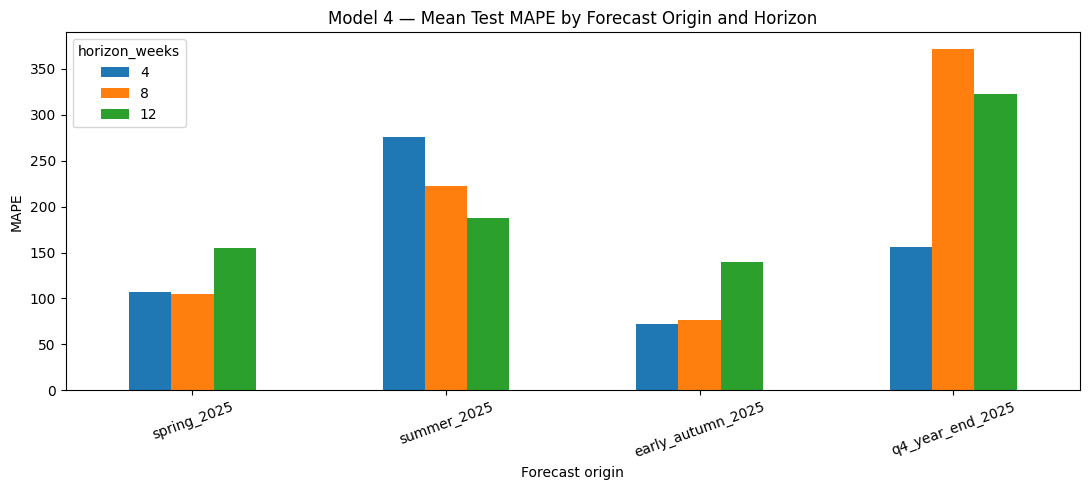

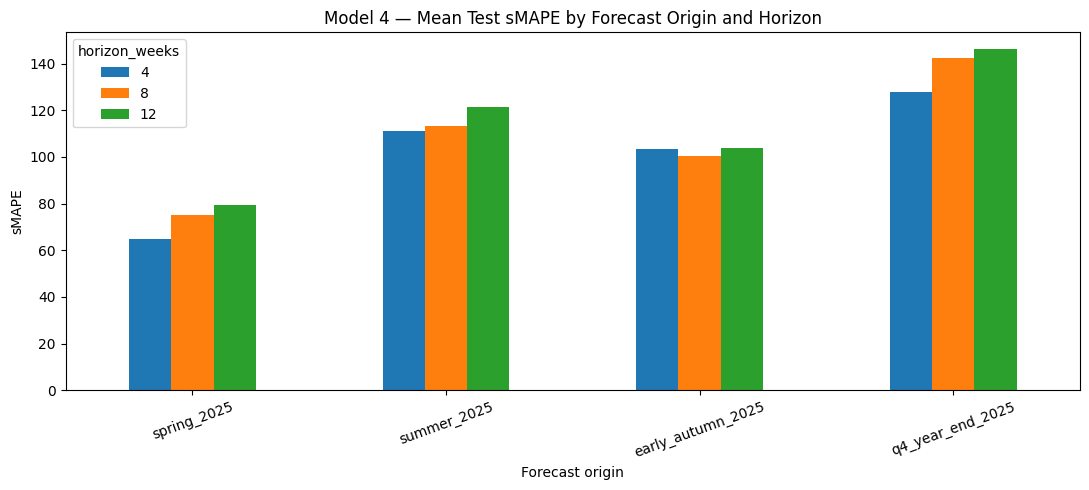

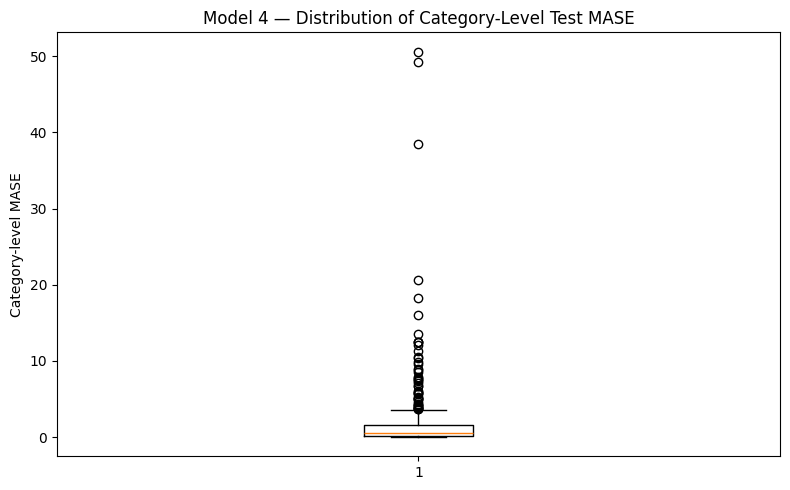

In [14]:
scenario_summary=(test_df.groupby(['scenario_id','outer_origin_label','horizon_weeks'],as_index=False)
    .agg(MAE=('MAE','mean'),RMSE=('RMSE','mean'),MAPE=('MAPE','mean'),sMAPE=('sMAPE','mean'),
         MASE=('MASE','mean'),median_MASE=('MASE','median'),valid_MASE_N=('MASE','count')))

overall_summary=pd.DataFrame([{
    'mean_MAE':test_df.MAE.mean(),'mean_RMSE':test_df.RMSE.mean(),
    'mean_MAPE':test_df.MAPE.mean(),'mean_sMAPE':test_df.sMAPE.mean(),
    'mean_MASE':test_df.MASE.mean(),'median_MASE':test_df.MASE.median(),
    'valid_MASE_evaluations':int(test_df.MASE.notna().sum()),
    'undefined_MASE_evaluations':int(test_df.MASE.isna().sum()),
    'n_outer_evaluations':len(test_df)
}])

scenario_summary.to_csv(OUT_DIR/'model_4_scenario_summary.csv',index=False,encoding='utf-8-sig')
overall_summary.to_csv(OUT_DIR/'model_4_overall_summary.csv',index=False,encoding='utf-8-sig')

print('SCENARIO SUMMARY'); display(scenario_summary)
print('OVERALL SUMMARY'); display(overall_summary)

for metric in ['MASE','MAE','RMSE','MAPE','sMAPE']:
    piv=scenario_summary.pivot(index='outer_origin_label',columns='horizon_weeks',values=metric).reindex(OUTER_ORIGINS.keys())
    ax=piv.plot(kind='bar',figsize=(11,5))
    ax.set_title(f'Model 4 — Mean Test {metric} by Forecast Origin and Horizon')
    ax.set_xlabel('Forecast origin'); ax.set_ylabel(metric)
    plt.xticks(rotation=20); plt.tight_layout()
    plt.savefig(OUT_DIR/f'plot_test_{metric.lower()}_by_origin_horizon.png',dpi=160); plt.show()

plt.figure(figsize=(8,5))
plt.boxplot(test_df.MASE.dropna(),vert=True)
plt.ylabel('Category-level MASE')
plt.title('Model 4 — Distribution of Category-Level Test MASE')
plt.tight_layout(); plt.savefig(OUT_DIR/'plot_category_mase_distribution.png',dpi=160); plt.show()

In [15]:
audit=[]

for label,origin_s in OUTER_ORIGINS.items():
    origin=pd.Timestamp(origin_s)
    for fold,vo,vdates in inner_folds(origin):
        audit.append({
            'check':f'{label}_fold{fold}_validation_before_outer',
            'passed':bool(vdates[-1] < origin),
            'detail':f'{vdates[0].date()} to {vdates[-1].date()} < {origin.date()}'
        })

audit += [
    {'check':'expected_outer_evaluations',
     'passed':len(test_df)==len(categories)*len(OUTER_ORIGINS)*len(FORECAST_HORIZONS),
     'detail':f'{len(test_df)} rows'},
    {'check':'no_missing_outer_predictions',
     'passed':not forecasts_df.y_pred.isna().any(),'detail':'weekly outer forecasts'},
    {'check':'nonnegative_predictions',
     'passed':bool((forecasts_df.y_pred>=0).all()),'detail':'all forecasts clipped at zero'},
    {'check':'mase_uses_52_week_scale',
     'passed':SEASONAL_PERIOD==52,'detail':f'm={SEASONAL_PERIOD}'},
    {'check':'optional_exog_lags_safe_for_max_horizon',
     'passed':all(l>=MAX_HORIZON for l in EXOG_LAGS),'detail':str(EXOG_LAGS)},
    {'check':'recursive_target_features',
     'passed':True,'detail':'future target lags/rolling features are built from working history with predictions'},
    {'check':'clustering_refit_by_temporal_cutoff',
     'passed':True,'detail':'profiles/scaler/clustering fit separately on each fold and outer pre-origin history'}
]
audit_df=pd.DataFrame(audit)
audit_df.to_csv(OUT_DIR/'model_4_integrity_audit.csv',index=False,encoding='utf-8-sig')
display(audit_df)
print('ALL AUDIT CHECKS PASSED:',bool(audit_df.passed.all()))

,check,passed,detail
0,spring_2025_fold1_validation_before_outer,True,2025-01-13 to 2025-02-03 < 2025-04-07
1,spring_2025_fold2_validation_before_outer,True,2025-02-10 to 2025-03-03 < 2025-04-07
2,spring_2025_fold3_validation_before_outer,True,2025-03-10 to 2025-03-31 < 2025-04-07
3,summer_2025_fold1_validation_before_outer,True,2025-04-14 to 2025-05-05 < 2025-07-07
4,summer_2025_fold2_validation_before_outer,True,2025-05-12 to 2025-06-02 < 2025-07-07
5,summer_2025_fold3_validation_before_outer,True,2025-06-09 to 2025-06-30 < 2025-07-07
6,early_autumn_2025_fold1_validation_before_outer,True,2025-06-16 to 2025-07-07 < 2025-09-08
7,early_autumn_2025_fold2_validation_before_outer,True,2025-07-14 to 2025-08-04 < 2025-09-08
8,early_autumn_2025_fold3_validation_before_outer,True,2025-08-11 to 2025-09-01 < 2025-09-08
9,q4_year_end_2025_fold1_validation_before_outer,True,2025-07-14 to 2025-08-04 < 2025-10-06


ALL AUDIT CHECKS PASSED: True


In [16]:
cv_diag=selected_df[['outer_origin_label','cv_mean_MASE']].copy()
test_diag=(test_df.groupby('outer_origin_label',as_index=False)
           .agg(test_mean_MASE=('MASE','mean'),test_median_MASE=('MASE','median')))
cv_diag=cv_diag.merge(test_diag,on='outer_origin_label',how='left')
cv_diag['test_minus_cv_MASE']=cv_diag.test_mean_MASE-cv_diag.cv_mean_MASE
cv_diag.to_csv(OUT_DIR/'model_4_cv_vs_test_diagnostic.csv',index=False,encoding='utf-8-sig')
display(cv_diag)

category_summary=(test_df.groupby(CATEGORY_COL,as_index=False)
                  .agg(mean_MASE=('MASE','mean'),median_MASE=('MASE','median'),
                       mean_MAE=('MAE','mean'),mean_RMSE=('RMSE','mean'),
                       mean_sMAPE=('sMAPE','mean'))
                  .sort_values('mean_MASE',ascending=False))
category_summary.to_csv(OUT_DIR/'model_4_category_summary.csv',index=False,encoding='utf-8-sig')
display(category_summary.head(15))

,outer_origin_label,cv_mean_MASE,test_mean_MASE,test_median_MASE,test_minus_cv_MASE
0,spring_2025,1.339598,1.226392,0.612210,-0.113206
1,summer_2025,0.618792,0.597396,0.361668,-0.021396
2,early_autumn_2025,0.339562,1.857427,0.750000,1.517865
3,q4_year_end_2025,0.917125,3.160143,0.907735,2.243018


,Product Category,mean_MASE,median_MASE,mean_MAE,mean_RMSE,mean_sMAPE
17,ΛΑΙΜΟΣ,11.526603,0.000000,1.139994,1.257816,50.000000
3,ΓΑΝΤΙ ΑΝΔΡΙΚΟ,6.077167,4.795339,15.829839,19.884412,126.518172
32,ΤΑΞΙΔΙΟΥ,5.119989,3.329932,3.639994,3.757816,100.000000
18,ΜΠΛΟΥΖΑ,4.104242,0.549107,1.312641,1.466485,103.472222
19,ΜΠΡΕΛΟΚ,3.197982,1.273148,2.197195,3.106922,59.027778
13,ΚΑΣΚΟΛ ΑΝΔΡΙΚΟ,3.004081,3.073053,194.712671,232.386769,103.028559
5,ΓΟΥΝΑ,2.838852,1.671203,22.071261,28.613448,103.495018
11,ΚAΣΚΟΛ,2.532489,0.779313,426.726900,586.012033,132.679279
30,ΣΚΟΥΦΟΣ ΑΝΔΡΙΚΟΣ,2.110640,1.716316,28.530181,35.728748,109.685168
12,ΚΑΠΑ,1.889383,1.425348,49.143156,65.444063,95.549392


In [18]:
experiment_log={
    'run_timestamp':datetime.now().strftime('%Y-%m-%d %H:%M:%S'),
    'model':'Model 4 - Cluster-Based Hierarchical / Hybrid Expert Forecasting',
    'outer_origins':OUTER_ORIGINS,
    'forecast_horizons':FORECAST_HORIZONS,
    'inner_cv_horizon':INNER_CV_HORIZON,
    'inner_cv_offsets_weeks':INNER_CV_OFFSETS_WEEKS,
    'seasonal_MASE_period':SEASONAL_PERIOD,
    'clustering_candidates':CLUSTER_CANDIDATES,
    'expert_ids':EXPERT_IDS,
    'forecast_features':FEATURE_COLS,
    'selection_rule':'12 clustering candidates; cluster experts selected temporally; clustering candidate scored with leave-one-fold-out expert selection; outer test untouched until final evaluation.',
    'multi_step_rule':'recursive ML forecasting; predicted target values are appended to working history.',
    'optional_exogenous_rule':f'only lags {EXOG_LAGS}; max forecast horizon {MAX_HORIZON}.'
}
with open(OUT_DIR/'model_4_experiment_log.json','w',encoding='utf-8') as f:
    json.dump(experiment_log,f,ensure_ascii=False,indent=2,default=str)

print('\nMODEL 4')
print(overall_summary.to_string(index=False))
print('Outputs saved to:',OUT_DIR)


MODEL 4
 mean_MAE  mean_RMSE  mean_MAPE  mean_sMAPE  mean_MASE  median_MASE  valid_MASE_evaluations  undefined_MASE_evaluations  n_outer_evaluations
70.656172  90.433673 187.388726  107.389743    1.71034     0.564621                     468                          12                  480
Outputs saved to: /content/drive/MyDrive/model_4_cluster_based_rolling_origin_outputs
